In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pickle

RESULT_DIR = '/Users/gabrieleaccarino/Workspace/waveletflux/notebooks/results/turbulent_radiative_layer_2D'

In [13]:
model_paths = {
    "WaveletFM-1scale": f'{RESULT_DIR}/WaveletFlow_turbulent_radiative_layer_2D_1scales_db2_rollout_nsampling_steps20_nensemble1_traj.pkl',
    "WaveletFM-3scales": f'{RESULT_DIR}/WaveletFlow_turbulent_radiative_layer_2D_3scales_db2_rollout_nsampling_steps20_nensemble1_traj.pkl',
}

# model data
rollout_traj = {}
for model, path in model_paths.items():
    with open(path, 'rb') as f:
        rollout_traj[model] = pickle.load(f)

# ground truth data
with open(f'{RESULT_DIR}/ground_truth_traj.pkl', 'rb') as f:
    truth_traj = pickle.load(f)


In [14]:
rollout_traj['WaveletFM-1scale'].shape, rollout_traj['WaveletFM-3scales'].shape, truth_traj.shape

(torch.Size([9, 1, 101, 128, 384, 4]),
 torch.Size([9, 1, 101, 128, 384, 4]),
 torch.Size([9, 101, 128, 384, 4]))

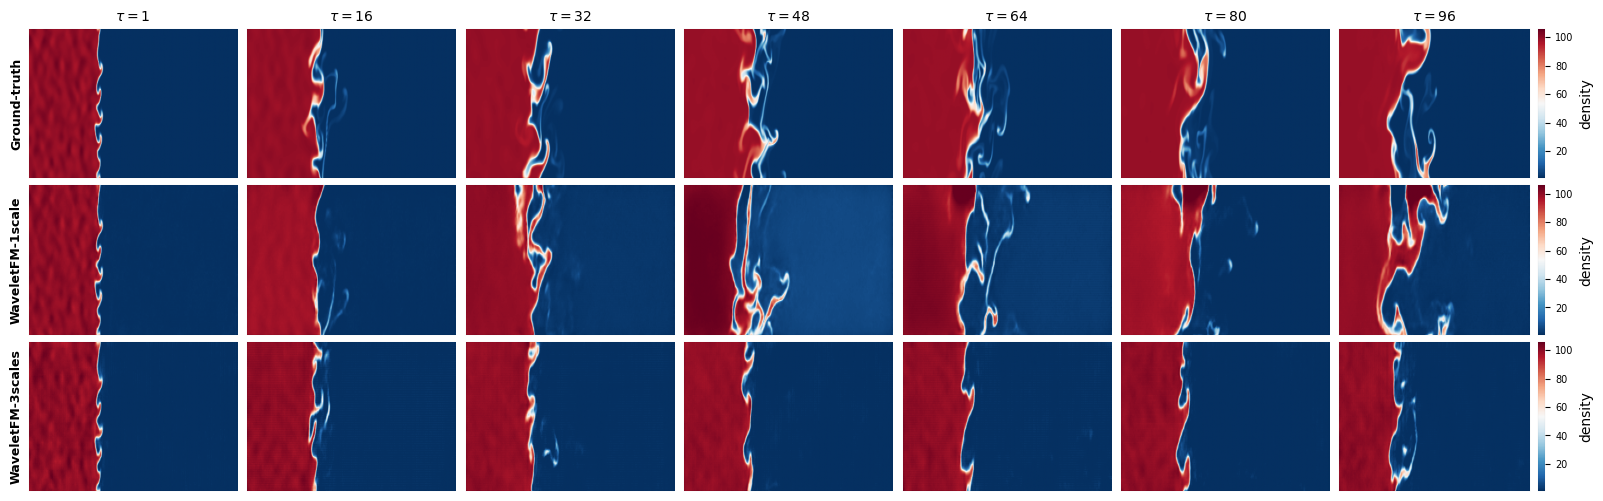

In [23]:
models_to_plot = ["WaveletFM-1scale", "WaveletFM-3scales"]
field_names    = ['density', 'pressure', 'velocity_x', 'velocity_y']

# ── Config ─────────────────────────────────────────────────────────────────────
TRAJ_IDX   = 8
ENS_IDX    = 0
Ti         = 4
field_idx  = 0
field_name = field_names[field_idx]
lead_times = [1, 16, 32, 48, 64, 80, 96]

# ── Frame helpers ──────────────────────────────────────────────────────────────
def get_gt_frame(tensor, traj_idx, lead, field):
    """
    tensor    : (T, H, W, C)
    traj_idx  : trajectory index
    lead      : 1-indexed rollout step
             lead=1 → physical frame Ti+1, i.e. tensor[Ti + lead - 1]
    """
    return tensor[traj_idx, Ti + lead - 1, :, :, field]          # numpy, no .cpu() needed

def get_pred_frame(tensor, traj_idx, ens_idx, lead, field):
    """
    tensor    : (rollout_steps, H, W, C)
    traj_idx  : trajectory index
    ens_idx   : ensemble index
    lead      : 1-indexed rollout step → index = lead - 1
    """
    return tensor[traj_idx, ens_idx, lead - 1, :, :, field]

# ── Results dict ───────────────────────────────────────────────────────────────

# ── Frames ─────────────────────────────────────────────────────────────────────
gt_frames = [get_gt_frame(truth_traj, TRAJ_IDX, t, field_idx) for t in lead_times]
model_frames = {
    name: [get_pred_frame(rollout_traj[name], TRAJ_IDX, ENS_IDX, t, field_idx) for t in lead_times]
    for name in models_to_plot
}

vmin = min(f.min() for f in gt_frames)
vmax = max(f.max() for f in gt_frames)

# ── Layout ─────────────────────────────────────────────────────────────────────
row_labels     = ["Ground-truth"] + models_to_plot
all_row_frames = [gt_frames] + [model_frames[name] for name in models_to_plot]
n_rows, n_cols = len(row_labels), len(lead_times)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(2.8 * n_cols, 2.0 * n_rows),
    gridspec_kw={"hspace": 0.05, "wspace": 0.05},
)
if n_rows == 1:
    axes = axes[None, :]

for ri, (frames, label) in enumerate(zip(all_row_frames, row_labels)):
    for ci, lead in enumerate(lead_times):
        ax = axes[ri, ci]
        im = ax.imshow(frames[ci], origin="lower", cmap="RdBu_r",
                       vmin=vmin, vmax=vmax, aspect="auto")
        ax.set_xticks([])
        ax.set_yticks([])
        if ci == 0:
            ax.set_ylabel(label, fontsize=9, fontweight="bold")
        if ri == 0:
            ax.set_title(rf"$\tau={lead}$", fontsize=10, fontweight="bold")

    plt.rcParams["axes.linewidth"] = 0.02
    cbar = fig.colorbar(im, ax=axes[ri, -1], fraction=0.046, pad=0.04, label=field_name)
    cbar.ax.tick_params(labelsize=7)

plt.show()